<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

Now that we have understood how a neural network with one hidden layer works, it is time to program it and apply it to different problems. The goal of this exercise is to retrieve the circles dataset and implement a network from scratch with one hidden layer and an arbitrary number of neurons. After understanding how it works, we will move on to a more concise version based on PyTorch.



In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_circles, make_moons, make_blobs
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import numpy as np

In [2]:
np.random.seed(123)
torch.manual_seed(123)

We go back to using the circles dataset that we used in MultiLogisticRegression.

In [3]:
X, y = make_circles(n_samples=1000, noise=0.1, factor=0.5, random_state=42)


X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float().unsqueeze(1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

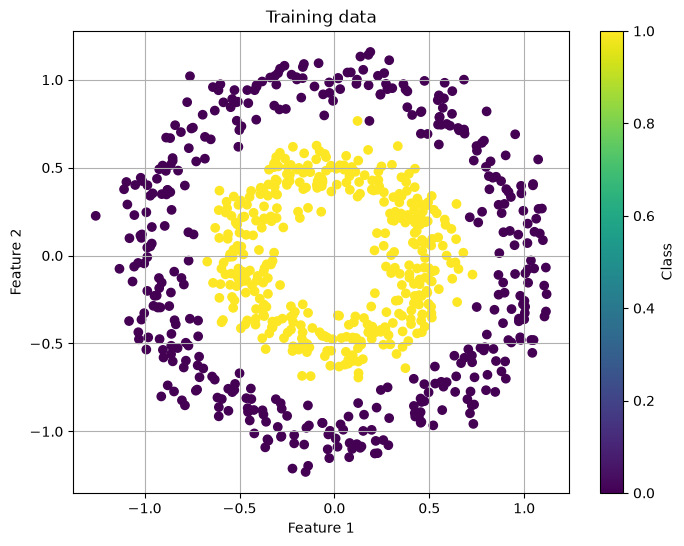

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.squeeze(), cmap='viridis', marker='o')
plt.title('Training data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Class')
plt.grid(True)
plt.show()

For the **from scratch** implementation of a neural network with one hidden layer, we will start by writing the code needed to implement the concept of a layer. As we mentioned, we must implement the constructor and the forward method:

* **init**: will take input\_size and output\_size, and must create and initialize the variables \$W\$ and \$b\$.
* forward: will apply the linear transformation of the inputs using the parameters.

Then, complete the MLP class that inherits from nn.Module. Remember that we must implement the constructor and the forward method:

* **init**: will take **input\_size** and **hidden\_size** as input parameters. The constructor must initialize the parameters \$W^{(1)}, b^{(1)}, W^{(2)}, b^{(2)}\$ according to the previously established dimensions. We will assume the output size is 1.
* **forward**: takes X, computes Z as a linear transformation, and applies the relu activation function. Finally, it applies the linear transformation of the output layer and a sigmoid activation function at the end.


In [5]:
class Layer(nn.Module):
  ##YOUR CODE HERE
    def __init__(self, input_size, output_size):
        super(Layer, self).__init__()
        self.W = nn.Parameter(torch.randn(input_size, output_size))
        self.b = nn.Parameter(torch.zeros(output_size))
    def forward(self, X):
        return torch.mm(X, self.W) + self.b

Now, let’s create a complete model called MLP. Again, when inheriting from nn.Module we must do:

* **init**: we will receive input\_size and hidden\_size. The constructor will instantiate two objects of the Layer class, one to model the hidden layer and another to model the output layer. We will assume that the output has size 1.
* **forward**: uses the relu function implementation to apply the activation function after the hidden layer.


In [6]:
class MLP(nn.Module):
    ##YOUR CODE HERE
    def __init__(self, input_size, hidden_size):
        super(MLP, self).__init__()
        self.hidden_layer = Layer(input_size, hidden_size)
        self.output_layer = Layer(hidden_size, 1)
        
    def forward(self, X):
        Z1 = self.hidden_layer(X)
        A1 = torch.relu(Z1)
        
        Z2 = self.output_layer(A1)
        out = torch.sigmoid(Z2)
        return out


In [7]:
def train_model(model, X_train, y_train, epochs=1000, lr=0.1):

    criterion = nn.BCELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()

        # Forward pass
        y_pred = model(X_train)

        # Loss calculation
        loss = criterion(y_pred, y_train)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch+1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')



As in the previous exercise, train a model with 3 hidden neurons for 10,000 iterations. Analyze the difference between the decision boundary using **"relu"** compared to that of MultiLogisticRegression.


In [8]:
epochs = 10000
n_hidden = 3

model = MLP(X_train.shape[1], n_hidden)
train_model(model, X_train, y_train, epochs=epochs)


Epoch [100/10000], Loss: 0.6439
Epoch [200/10000], Loss: 0.6196
Epoch [300/10000], Loss: 0.5926
Epoch [400/10000], Loss: 0.5652
Epoch [500/10000], Loss: 0.5418
Epoch [600/10000], Loss: 0.5208
Epoch [700/10000], Loss: 0.4991
Epoch [800/10000], Loss: 0.4629
Epoch [900/10000], Loss: 0.4028
Epoch [1000/10000], Loss: 0.3413
Epoch [1100/10000], Loss: 0.2933
Epoch [1200/10000], Loss: 0.2575
Epoch [1300/10000], Loss: 0.2304
Epoch [1400/10000], Loss: 0.2090
Epoch [1500/10000], Loss: 0.1919
Epoch [1600/10000], Loss: 0.1780
Epoch [1700/10000], Loss: 0.1666
Epoch [1800/10000], Loss: 0.1568
Epoch [1900/10000], Loss: 0.1485
Epoch [2000/10000], Loss: 0.1412
Epoch [2100/10000], Loss: 0.1347
Epoch [2200/10000], Loss: 0.1289
Epoch [2300/10000], Loss: 0.1237
Epoch [2400/10000], Loss: 0.1191
Epoch [2500/10000], Loss: 0.1149
Epoch [2600/10000], Loss: 0.1111
Epoch [2700/10000], Loss: 0.1076
Epoch [2800/10000], Loss: 0.1044
Epoch [2900/10000], Loss: 0.1014
Epoch [3000/10000], Loss: 0.0987
Epoch [3100/10000],

In [9]:

def plot_decision_boundary(model, X, y):
    model.eval()
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    grid_tensor = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()]).float()
    Z = model(grid_tensor)
    Z = Z.detach().numpy().reshape(xx.shape)

    plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=1)

    y_pred_probs = model(X)
    y_pred_classes = (y_pred_probs > 0.5).float()

    plt.scatter(X[:, 0], X[:, 1], c=y_pred_classes.squeeze(), cmap=plt.cm.coolwarm, edgecolors='k') # Usar coolwarm para los puntos coloreados por predicción
    plt.title("Decision boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

/tmp/ipykernel_434435/585849756.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_434435/585849756.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


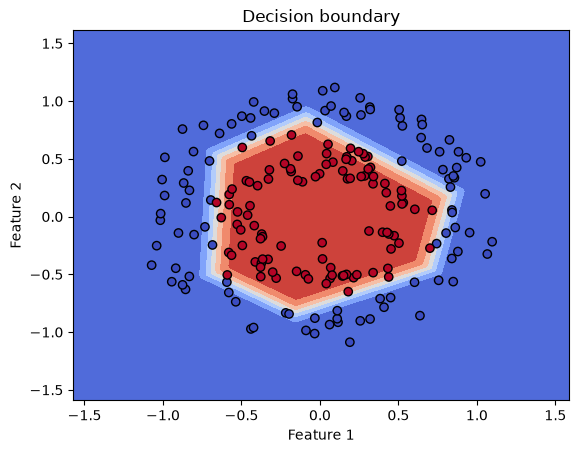

In [10]:
plot_decision_boundary(model, X_test, y_test)

Next, we are going to enrich the MLP class with the ability to use other activation functions. To do this, add **activation\_function** as an input parameter in the constructor. Inside it, complete and add this piece of code:

```python
if activation_function == "relu":
    self.activation_function = nn.ReLU()
elif activation_function == "tanh":
    self.activation_function = nn.Tanh()
elif activation_function == "sigmoid":
    self.activation_function = nn.Sigmoid()
else:
    raise ValueError("Unsupported activation function")
```


In [11]:
class MLP(nn.Module):
    ##YOUR CODE HERE
    def __init__(self, input_size, hidden_size, activation_function):
        super(MLP, self).__init__()

        if activation_function == "relu":
            self.activation_function = nn.ReLU()
        elif activation_function == "tanh":
            self.activation_function = nn.Tanh()
        elif activation_function == "sigmoid":
            self.activation_function = nn.Sigmoid()
        else:
            raise ValueError("Unsupported activation function")
        self.hidden_layer = Layer(input_size, hidden_size)
        self.output_layer = Layer(hidden_size, 1)
        
    def forward(self, X):
        Z1 = self.hidden_layer(X)
        A1 = self.activation_function(Z1)
        
        Z2 = self.output_layer(A1)
        out = torch.sigmoid(Z2)
        return out

Now, using the configuration of 3 hidden neurons, compare the results of training a network with the relu, sigmoid, and tanh activation functions. Check the existing differences:

* Do they all have the same convergence speed?
* Do they all reach the same decision boundary?
* Do they all take the same time to run?


In [12]:
epochs = 10000
n_hidden = 3

model_relu = MLP(X_train.shape[1], n_hidden, activation_function='relu')
train_model(model_relu, X_train, y_train, epochs=epochs)

Epoch [100/10000], Loss: 0.6580
Epoch [200/10000], Loss: 0.6347
Epoch [300/10000], Loss: 0.6008
Epoch [400/10000], Loss: 0.5532
Epoch [500/10000], Loss: 0.4960
Epoch [600/10000], Loss: 0.4367
Epoch [700/10000], Loss: 0.3810
Epoch [800/10000], Loss: 0.3321
Epoch [900/10000], Loss: 0.2903
Epoch [1000/10000], Loss: 0.2555
Epoch [1100/10000], Loss: 0.2270
Epoch [1200/10000], Loss: 0.2037
Epoch [1300/10000], Loss: 0.1844
Epoch [1400/10000], Loss: 0.1687
Epoch [1500/10000], Loss: 0.1558
Epoch [1600/10000], Loss: 0.1448
Epoch [1700/10000], Loss: 0.1355
Epoch [1800/10000], Loss: 0.1277
Epoch [1900/10000], Loss: 0.1210
Epoch [2000/10000], Loss: 0.1152
Epoch [2100/10000], Loss: 0.1102
Epoch [2200/10000], Loss: 0.1057
Epoch [2300/10000], Loss: 0.1018
Epoch [2400/10000], Loss: 0.0983
Epoch [2500/10000], Loss: 0.0952
Epoch [2600/10000], Loss: 0.0924
Epoch [2700/10000], Loss: 0.0899
Epoch [2800/10000], Loss: 0.0876
Epoch [2900/10000], Loss: 0.0855
Epoch [3000/10000], Loss: 0.0836
Epoch [3100/10000],

In [13]:
model_tanh = MLP(X_train.shape[1], n_hidden, activation_function='tanh')
train_model(model_tanh, X_train, y_train, epochs=epochs)

Epoch [100/10000], Loss: 0.6858
Epoch [200/10000], Loss: 0.6687
Epoch [300/10000], Loss: 0.6468
Epoch [400/10000], Loss: 0.6181
Epoch [500/10000], Loss: 0.5855
Epoch [600/10000], Loss: 0.5505
Epoch [700/10000], Loss: 0.5119
Epoch [800/10000], Loss: 0.4683
Epoch [900/10000], Loss: 0.4225
Epoch [1000/10000], Loss: 0.3791
Epoch [1100/10000], Loss: 0.3414
Epoch [1200/10000], Loss: 0.3099
Epoch [1300/10000], Loss: 0.2839
Epoch [1400/10000], Loss: 0.2623
Epoch [1500/10000], Loss: 0.2441
Epoch [1600/10000], Loss: 0.2288
Epoch [1700/10000], Loss: 0.2157
Epoch [1800/10000], Loss: 0.2045
Epoch [1900/10000], Loss: 0.1948
Epoch [2000/10000], Loss: 0.1864
Epoch [2100/10000], Loss: 0.1790
Epoch [2200/10000], Loss: 0.1724
Epoch [2300/10000], Loss: 0.1665
Epoch [2400/10000], Loss: 0.1613
Epoch [2500/10000], Loss: 0.1566
Epoch [2600/10000], Loss: 0.1523
Epoch [2700/10000], Loss: 0.1484
Epoch [2800/10000], Loss: 0.1448
Epoch [2900/10000], Loss: 0.1415
Epoch [3000/10000], Loss: 0.1385
Epoch [3100/10000],

In [14]:
model_sigmoid = MLP(X_train.shape[1], n_hidden, activation_function='sigmoid')
train_model(model_sigmoid, X_train, y_train, epochs=epochs)

Epoch [100/10000], Loss: 0.6950
Epoch [200/10000], Loss: 0.6947
Epoch [300/10000], Loss: 0.6945
Epoch [400/10000], Loss: 0.6942
Epoch [500/10000], Loss: 0.6941
Epoch [600/10000], Loss: 0.6939
Epoch [700/10000], Loss: 0.6938
Epoch [800/10000], Loss: 0.6937
Epoch [900/10000], Loss: 0.6935
Epoch [1000/10000], Loss: 0.6934
Epoch [1100/10000], Loss: 0.6934
Epoch [1200/10000], Loss: 0.6933
Epoch [1300/10000], Loss: 0.6932
Epoch [1400/10000], Loss: 0.6931
Epoch [1500/10000], Loss: 0.6931
Epoch [1600/10000], Loss: 0.6930
Epoch [1700/10000], Loss: 0.6929
Epoch [1800/10000], Loss: 0.6929
Epoch [1900/10000], Loss: 0.6928
Epoch [2000/10000], Loss: 0.6928
Epoch [2100/10000], Loss: 0.6927
Epoch [2200/10000], Loss: 0.6926
Epoch [2300/10000], Loss: 0.6926
Epoch [2400/10000], Loss: 0.6925
Epoch [2500/10000], Loss: 0.6924
Epoch [2600/10000], Loss: 0.6923
Epoch [2700/10000], Loss: 0.6922
Epoch [2800/10000], Loss: 0.6921
Epoch [2900/10000], Loss: 0.6920
Epoch [3000/10000], Loss: 0.6919
Epoch [3100/10000],

/tmp/ipykernel_434435/585849756.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
/tmp/ipykernel_434435/585849756.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.arange(y_min, y_max, 0.02))


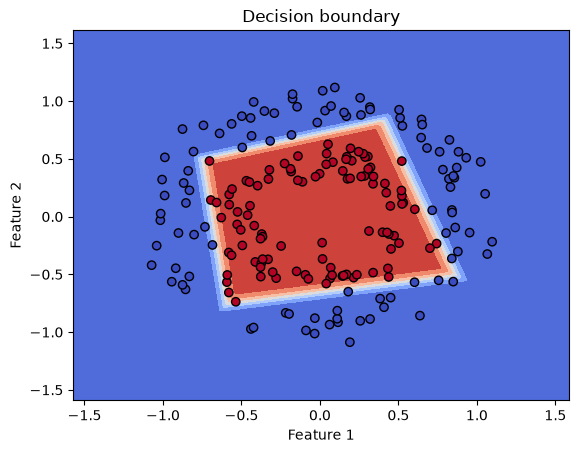

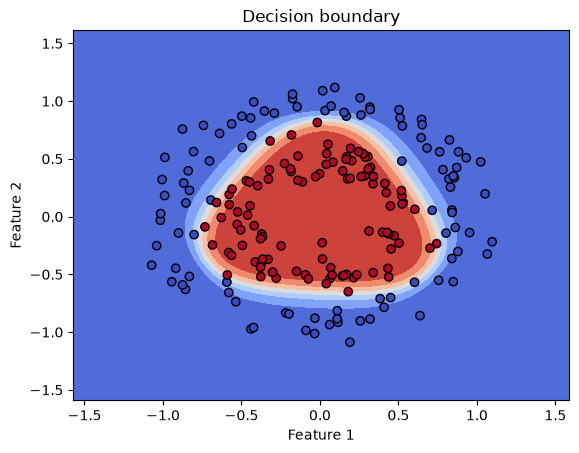

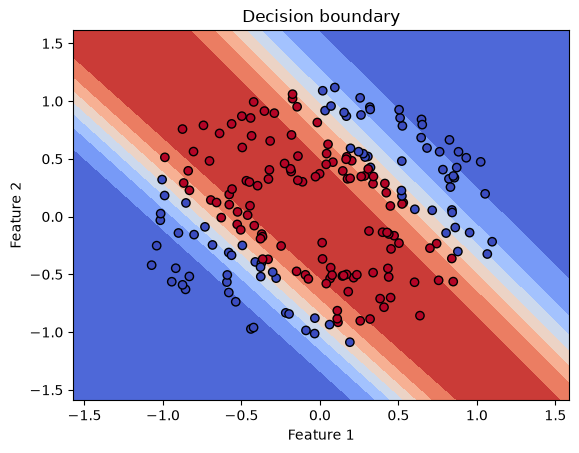

In [15]:
plot_decision_boundary(model_relu, X_test, y_test)
plot_decision_boundary(model_tanh, X_test, y_test)
plot_decision_boundary(model_sigmoid, X_test, y_test)

Now, fixing relu as the activation function, let’s analyze how the number of neurons affects the MLP. Try with 2, 8, and 128. Adjust the number of iterations if any of them do not fully converge (except for the case with 2, which we already know will get stuck).


In [16]:
epochs = 10000
n_hidden_list = [2, 8, 128]
activation_function='relu'

for n_hidden in n_hidden_list:
    model_relu = MLP(X_train.shape[1], n_hidden, activation_function=activation_function)
    train_model(model_relu, X_train, y_train, epochs=epochs)
    plot_decision_boundary(model_relu, X_test, y_test)
    

Epoch [100/10000], Loss: 0.6271
Epoch [200/10000], Loss: 0.5944
Epoch [300/10000], Loss: 0.5774
Epoch [400/10000], Loss: 0.5648
Epoch [500/10000], Loss: 0.5552


KeyboardInterrupt: 

Observe the differences in the decision boundary depending on the number of neurons in the hidden layer. What do you think is the reason for this?


Next, you have the same dataset but with a higher amount of noise, which will create more overlap between the classes. Repeat the generation of 3 models with 3, 8, and 128 neurons. Do you observe any changes compared to the previous exercise?



In [ ]:
X, y = make_circles(n_samples=1000, noise=0.2, factor=0.5, random_state=42)

# Convertimos los datos a tensores de PyTorch
X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float().unsqueeze(1) # Aseguramos que y tenga la forma (n_samples, 1)

# Dividimos los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.squeeze(), cmap='viridis', marker='o')
plt.title('Training data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Class')
plt.grid(True)
plt.show()

In [ ]:
epochs = 10000
n_hidden_list = [2, 8, 128]
activation_function='relu'

for n_hidden in n_hidden_list:
    model_relu = MLP(X_train.shape[1], n_hidden, activation_function=activation_function)
    train_model(model_relu, X_train, y_train, epochs=epochs)
    plot_decision_boundary(model_relu, X_test, y_test)

### From 2 to many classes

We continue improving our **from scratch** MLP, this time modifying the output layer to handle multi-class problems. First, we will generate synthetic data for 5 classes. Note that the output **y** changes in format (dimension and type) compared to the previous code. This is done so that it works with the new cost function.


In [ ]:
X, y = make_blobs(n_samples=10000, centers=5, cluster_std=2, random_state=42)

X = torch.from_numpy(X).float()
y = torch.from_numpy(y).long() 

#
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.squeeze(), cmap='viridis', marker='o')
plt.title('Training data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Class')
plt.grid(True)
plt.show()

Now, modify the MLP class by adding a new constructor parameter **num\_outputs**, so that the parameters $W^{(2)}, b^{(2)}$ match the new size. In the forward method, we should return only the linear transformation of the second layer, without applying any activation function. Also, modify what is necessary in the training loop and in the function for plotting the decision boundary to work with the new cost function.


In [ ]:
class MLP(nn.Module):
    ##YOUR CODE HERE
    def __init__(self, input_size, hidden_size, activation_function, num_outputs):
        super(MLP, self).__init__()

        if activation_function == "relu":
            self.activation_function = nn.ReLU()
        elif activation_function == "tanh":
            self.activation_function = nn.Tanh()
        elif activation_function == "sigmoid":
            self.activation_function = nn.Sigmoid()
        else:
            raise ValueError("Unsupported activation function")
        self.hidden_layer = Layer(input_size, hidden_size)
        self.output_layer = Layer(hidden_size, num_outputs)
        
    def forward(self, X):
        Z1 = self.hidden_layer(X)
        A1 = self.activation_function(Z1)
        
        Z2 = self.output_layer(A1)
        #out = torch.sigmoid(Z2)
        return Z2

In [ ]:
def train_model(model, X_train, y_train, epochs=1000, lr=0.1):
    ##code here
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    y_train = y_train.squeeze().long()

    for epoch in range(epochs):
        model.train()

        y_pred = model(X_train)

        loss = criterion(y_pred, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')



In [ ]:
def plot_decision_boundary(model, X, y):
    
    ##code here
    model.eval()
    
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    grid_tensor = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()]).float()
    
    with torch.no_grad():
        grid_logits = model(grid_tensor)
        grid_preds = torch.argmax(grid_logits, dim=1)
        Z = grid_preds.numpy().reshape(xx.shape)

        y_logits = model(X)
        y_pred_classes = torch.argmax(y_logits, dim=1)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap=plt.cm.viridis, alpha=0.6)

    plt.scatter(X[:, 0].numpy(), X[:, 1].numpy(), c=y_pred_classes.numpy(), cmap=plt.cm.viridis, edgecolors='k', alpha=0.8)
    plt.title("Multi-class Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.colorbar(label='Predicted Class')
    plt.grid(True)
    plt.show()


In [ ]:
input_size = 2          
hidden_size = 16        
num_outputs = 5         
activation = "relu"

model = MLP(input_size=input_size, hidden_size=hidden_size, activation_function=activation, num_outputs=num_outputs)
train_model(model=model, X_train=X_train, y_train=y_train, epochs=1000, lr=0.05)

plot_decision_boundary(model, X_test, y_test)

### Short Assignment

For this assignment, you will work with the dataset provided. Your task is to implement a single hidden layer MLP with a fixed numer of neurons and compare the proposed activation functions (ReLU, Sigmoid, Tanh).

You should analyze and report on the following aspects:

- Convergence: How quickly each model reaches a stable solution.

- Training and Test Error: Compare performance on the training and test sets.


- Computational Efficiency: Note any differences in training time for different configurations.
- ...

Repeat each configuration with at least 5 different random seeds and report mean ± standard deviation. State explicitly which of the observed differences you consider real and which fall within run-to-run variability

Finally, **submit a report** with a maximum length of 2 pages, summarizing your implementation, results, visualizations, and conclusions. Include any interesting observations or comparisons that go beyond the main requirements.

In [ ]:
data = torch.load("mnist_subsample.pt")
X_train = data["X_train"]
y_train = data["y_train"]
X_test = data["X_test"]
y_test = data["y_test"]

In [ ]:
print(f"X_train shape: {X_train.shape} | type: {X_train.dtype}")
print(f"y_train shape: {y_train.shape} | type: {y_train.dtype}")
print(f"X_test shape:  {X_test.shape}  | type: {X_test.dtype}")
print(f"y_test shape:   {y_test.shape}   | type: {y_test.dtype}")

num_classes = len(torch.unique(y_train))
print(f"\nNumber of classes: {num_classes}")

In [ ]:
np.sqrt(784)

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    img = X_train[i].view(28, 28) if X_train[i].dim() == 1 else X_train[i].squeeze()
    
    axes[i].imshow(img.numpy(), cmap='gray')
    axes[i].set_title(f"Clase: {y_train[i].item()}")
    axes[i].axis('off')

plt.suptitle("Samples of MNIST dataset Subsample", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        preds = torch.argmax(logits, dim=1)
        acc = (preds == y).float().mean().item() * 100
    return acc

def train_model(model, X_train, y_train, epochs=1000, lr=0.1):
    ##code here
    loss_history = []
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    #y_train = y_train.squeeze().long()

    for epoch in range(epochs):
        model.train()

        y_pred = model(X_train)

        loss = criterion(y_pred, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')
    return loss_history

In [ ]:
input_size = X_train.shape[1]                
num_outputs = len(torch.unique(y_train))     
hidden_size = 12

In [ ]:
import time
activations = ["relu", "sigmoid", "tanh"]
seeds = [123, 124, 125, 126, 127]
results = {act: [] for act in activations}
loss_histories = {act: [] for act in activations}

epochs = 10000
lr = 0.1

for act in activations:
    print(f"--- Evaluating activation function: {act.upper()} ---")
    for s in seeds:
        torch.manual_seed(s)
        np.random.seed(s)
        
        model = MLP(input_size=input_size, hidden_size=hidden_size, activation_function=act, num_outputs=num_outputs)
        
        start_time = time.time()
        
        history = train_model(model, X_train, y_train, epochs=epochs, lr=lr)
        
        elapsed_time = time.time() - start_time

        loss_histories[act].append(history)
        
        train_acc = evaluate_accuracy(model, X_train, y_train)
        test_acc = evaluate_accuracy(model, X_test, y_test)
        
        results[act].append({"train_acc": train_acc,"test_acc": test_acc,"time": elapsed_time})

In [ ]:
print("\n" + "="*80)
print(f"{'Activation':<12} | {'Train Acc (%)':<18} | {'Test Acc (%)':<18} | {'Time (s)':<16}")
print("="*80)

for act in activations:
    tr_accs = [r["train_acc"] for r in results[act]]
    te_accs = [r["test_acc"] for r in results[act]]
    times = [r["time"] for r in results[act]]
    
    print(f"{act.capitalize():<12} | "
          f"{np.mean(tr_accs):.2f} ± {np.std(tr_accs):.2f}     | "
          f"{np.mean(te_accs):.2f} ± {np.std(te_accs):.2f}     | "
          f"{np.mean(times):.3f} ± {np.std(times):.3f}")

In [ ]:
plt.figure(figsize=(10, 6))

for act in activations:
    arr = np.array(loss_histories[act])
    mean_loss = np.mean(arr, axis=0)
    std_loss = np.std(arr, axis=0)
    epochs_range = np.arange(1, epochs + 1)

    plt.plot(epochs_range, mean_loss, label=f'{act.upper()} (Average)', linewidth=2)
    plt.fill_between(np.arange(1, epochs + 1), mean_loss - std_loss, mean_loss + std_loss, alpha=0.15)

plt.title("Loss graph", fontsize=14)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extraer métricas desde el diccionario 'results'
activations_list = [act.upper() for act in activations]

train_acc_means = [np.mean([r["train_acc"] for r in results[act]]) for act in activations]
train_acc_stds = [np.std([r["train_acc"] for r in results[act]]) for act in activations]

test_acc_means = [np.mean([r["test_acc"] for r in results[act]]) for act in activations]
test_acc_stds = [np.std([r["test_acc"] for r in results[act]]) for act in activations]

time_means = [np.mean([r["time"] for r in results[act]]) for act in activations]
time_stds = [np.std([r["time"] for r in results[act]]) for act in activations]

# ==========================================
# Chart 1: Accuracy Comparison (Train vs Test)
# ==========================================
x = np.arange(len(activations_list))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

rects1 = ax.bar(x - width/2, train_acc_means, width, yerr=train_acc_stds, label='Training Accuracy', capsize=5, color='#2b5c8f')
rects2 = ax.bar(x + width/2, test_acc_means, width, yerr=test_acc_stds, label='Test Accuracy', capsize=5, color='#d95f02')

ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Model Performance Across Activation Functions (Mean ± Std)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(activations_list, fontsize=11)
ax.set_ylim(0, 110)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.6)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 6),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('accuracy_comparison.png', dpi=300)
plt.show()

# ==========================================
# Chart 2: Computational Efficiency (Training Time) - FIXED
# ==========================================
fig, ax = plt.subplots(figsize=(7, 4.5))

colors = ['#2b5c8f', '#d95f02', '#2ca02c']
bars = ax.bar(activations_list, time_means, yerr=time_stds, capsize=5, color=colors, width=0.45, alpha=0.85)

ax.set_ylabel('Training Time (seconds)', fontsize=12)
ax.set_title('Computational Efficiency Across Activations', fontsize=13, fontweight='bold')

# CORRECCIÓN: Ajustar el límite superior considerando la desviación estándar máxima
max_time_with_std = max([m + s for m, s in zip(time_means, time_stds)])
ax.set_ylim(0, max_time_with_std * 1.15)

ax.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f} s',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('training_time_comparison.png', dpi=300)
plt.show()